# IPL Ball-by-Ball EDA: validated analysis and Power BI exports

This notebook audits the supplied delivery-level CSV, derives only metrics supported by its fields, and exports documented Power BI tables.

**Business question.** What can delivery-level IPL data reliably tell us about scoring, batting, bowling, and team performance across the seasons actually present?

**Scope.** Descriptive analysis of the supplied file. No causal claims. A season appearing in the file does not establish that its data is complete.


## Source data, schema, and limitations

The source file is `ball_by_ball_data.csv`. It contains one record per delivery and 30 original columns: `season_id`, `match_id`, `batter`, `bowler`, `non_striker`, `team_batting`, `team_bowling`, `over_number`, `ball_number`, `batter_runs`, `extras`, `total_runs`, `batsman_type`, `bowler_type`, `player_out`, `fielders_involved`, `is_wicket`, `is_wide_ball`, `is_no_ball`, `is_leg_bye`, `is_bye`, `is_penalty`, `wide_ball_runs`, `no_ball_runs`, `leg_bye_runs`, `bye_runs`, `penalty_runs`, `wicket_kind`, `is_super_over`, and `innings`.

The supplied CSV already has `season_id` as a column, so it is read without `index_col` and does not need index restoration. The raw frame remains unchanged; cleaning and features are created on a separate copy. `match_id` and team IDs are identifiers, not measures.

The file does **not** contain genuine match dates, venues, tosses, or match winners. Local repository inspection and metadata searches did not identify a supplementary match table with a validated `match_id` relationship. Consequently, match-result, venue, title, toss, and chase analyses are excluded. Team names are not assigned without a verified mapping; numeric IDs are retained and audited.

`over_number` and `ball_number` are zero-based in the source. Regulation powerplay, middle, and death phases are defined as over indices 0–5, 6–14, and 15–19. Super-over deliveries are kept separate and excluded from regulation batting, bowling, and team-season statistics.


In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 30)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})

configured_path = os.environ.get("IPL_DATA_PATH")
if configured_path:
    data_candidates = [Path(configured_path).expanduser()]
else:
    data_candidates = [
        Path.cwd() / "ball_by_ball_data.csv",
        Path("/content/drive/MyDrive/ball_by_ball_data.csv"),
        Path("/content/ball_by_ball_data.csv"),
    ]

DATA_PATH = next((candidate.resolve() for candidate in data_candidates if candidate.is_file()), None)
if DATA_PATH is None:
    searched = "\n".join(f"- {candidate}" for candidate in data_candidates)
    raise FileNotFoundError(
        "Could not find ball_by_ball_data.csv. Set IPL_DATA_PATH to the source CSV path "
        f"or place it in the notebook's working directory. Searched:\n{searched}"
    )

raw_df = pd.read_csv(DATA_PATH)
df = raw_df.copy(deep=True)
original_columns = raw_df.columns.tolist()
source_row_count = len(raw_df)
required_columns = {
    "season_id", "match_id", "batter", "bowler", "team_batting", "team_bowling",
    "over_number", "ball_number", "batter_runs", "extras", "total_runs", "is_wicket",
    "is_wide_ball", "is_no_ball", "is_leg_bye", "is_bye", "is_penalty",
    "wide_ball_runs", "no_ball_runs", "leg_bye_runs", "bye_runs", "penalty_runs",
    "wicket_kind", "is_super_over", "innings",
}
missing_required = sorted(required_columns.difference(df.columns))
if missing_required:
    raise ValueError(f"Source CSV is missing required columns: {missing_required}")

print(f"Source: {DATA_PATH}")
print(f"Loaded {source_row_count:,} delivery rows and {len(df.columns)} source columns.")


Source: D:\Srihi_career\Srihi_Projects\IPL-data-2008-2026-EDA\ball_by_ball_data.csv
Loaded 288,226 delivery rows and 30 source columns.


## Initial exploration and source checks

These summaries are calculated from the source rather than assuming uninterrupted season coverage. Missing dismissal fields and player-type attributes are retained and reported instead of being replaced with invented labels.


In [2]:
season_coverage = sorted(df["season_id"].dropna().unique().tolist())
match_count = df["match_id"].nunique(dropna=True)
batting_team_ids = sorted(df["team_batting"].dropna().unique().tolist())
bowling_team_ids = sorted(df["team_bowling"].dropna().unique().tolist())
player_count = len(
    set(df["batter"].dropna().astype(str))
    | set(df["bowler"].dropna().astype(str))
    | set(df["non_striker"].dropna().astype(str))
)

overview = pd.DataFrame(
    {
        "measure": [
            "Delivery rows", "Source columns", "Observed seasons", "Unique matches",
            "Unique batting team IDs", "Unique bowling team IDs", "Unique players",
            "Exact duplicate rows",
        ],
        "value": [
            len(df), len(df.columns), season_coverage, match_count,
            len(batting_team_ids), len(bowling_team_ids), player_count, int(df.duplicated().sum()),
        ],
    }
)
display(overview)
display(
    df.groupby("season_id", as_index=False)
    .agg(matches=("match_id", "nunique"), deliveries=("match_id", "size"))
    .sort_values("season_id")
)

print("Source dtypes:")
display(df.dtypes.rename("dtype").to_frame())
print("Source missingness:")
display(
    df.isna().sum().rename("missing_rows").to_frame()
    .assign(missing_percent=lambda table: (table["missing_rows"] / len(df) * 100).round(2))
)
innings_per_match = df.groupby("match_id")["innings"].nunique()
print("Innings identifiers per match (includes super overs):")
display(innings_per_match.value_counts().sort_index().rename_axis("innings_count").to_frame("matches"))


,measure,value
0,Delivery rows,288226
1,Source columns,30
2,Observed seasons,"[2008, 2009, 2010, 2011, 2012, 2013, 2014, 201..."
3,Unique matches,1212
4,Unique batting team IDs,14
5,Unique bowling team IDs,14
6,Unique players,795
7,Exact duplicate rows,0


,season_id,matches,deliveries
0,2008,58,13489
1,2009,57,13606
2,2010,60,14498
3,2011,73,17013
4,2012,74,17767
5,2013,76,18177
6,2014,60,14300
7,2015,59,13652
8,2016,60,14096
9,2017,59,13862


Source dtypes:


,dtype
season_id,int64
match_id,int64
batter,object
bowler,object
non_striker,object
team_batting,int64
team_bowling,int64
over_number,int64
ball_number,int64
batter_runs,int64


Source missingness:


,missing_rows,missing_percent
season_id,0,0.00
match_id,0,0.00
batter,0,0.00
bowler,0,0.00
non_striker,0,0.00
team_batting,0,0.00
team_bowling,0,0.00
over_number,0,0.00
ball_number,0,0.00
batter_runs,0,0.00


Innings identifiers per match (includes super overs):


,matches
innings_count,
1,6
2,1190
4,15
6,1


## Data quality assessment and conservative cleaning

Whitespace is stripped from player and text attributes without changing initials or surnames. No team-name mapping is applied: the old notebook's mapping is not backed by source documentation, and several source IDs are missing from it. Missing optional attributes remain missing. No rows are removed.

The delivery key is checked using `(season_id, match_id, innings, over_number, ball_number)`. The source's zero-based over/ball numbering and its actual key uniqueness are verified before using those fields for ordering.


In [3]:
quality_checks = []


def add_check(name, passed, observed, expected, details="", warning=False, info=False):
    status = "INFO" if info else ("PASS" if passed else ("WARN" if warning else "FAIL"))
    quality_checks.append(
        {
            "check_name": name,
            "status": status,
            "observed": str(observed),
            "expected": str(expected),
            "details": details,
        }
    )


identifier_columns = ["season_id", "team_batting", "team_bowling", "innings", "over_number", "ball_number"]
integer_columns = [
    "batter_runs", "extras", "total_runs", "wide_ball_runs", "no_ball_runs",
    "leg_bye_runs", "bye_runs", "penalty_runs",
]
for column in identifier_columns + integer_columns:
    numeric = pd.to_numeric(df[column], errors="raise")
    if numeric.isna().any() or not np.equal(numeric, np.floor(numeric)).all():
        raise ValueError(f"{column} contains missing or non-integer values.")
    df[column] = numeric.astype("int64")

df["match_id"] = df["match_id"].astype("string").str.strip()
if df["match_id"].isna().any() or df["match_id"].eq("").any():
    raise ValueError("match_id contains missing or blank identifiers.")

text_columns = [
    "batter", "bowler", "non_striker", "batsman_type", "bowler_type",
    "player_out", "fielders_involved", "wicket_kind",
]
for column in text_columns:
    if column in df:
        df[column] = df[column].astype("string").str.strip()
        df[column] = df[column].mask(df[column].eq(""))

boolean_columns = [
    "is_wicket", "is_wide_ball", "is_no_ball", "is_leg_bye",
    "is_bye", "is_penalty", "is_super_over",
]
for column in boolean_columns:
    if df[column].isna().any() or not df[column].isin([True, False]).all():
        raise ValueError(f"{column} contains missing or non-Boolean values.")
    df[column] = df[column].astype("boolean")

delivery_key = ["season_id", "match_id", "innings", "over_number", "ball_number"]
exact_duplicate_count = int(df.duplicated().sum())
delivery_duplicate_count = int(df.duplicated(delivery_key, keep=False).sum())
multi_season_matches = int((df.groupby("match_id")["season_id"].nunique() > 1).sum())
team_ids = sorted(int(value) for value in (set(df["team_batting"].unique()) | set(df["team_bowling"].unique())))
team_audit = (
    pd.concat(
        [
            df.groupby("team_batting").size().rename("batting_deliveries"),
            df.groupby("team_bowling").size().rename("bowling_deliveries"),
        ],
        axis=1,
    )
    .fillna(0)
    .astype("int64")
    .rename_axis("team_id")
    .reset_index()
)
team_audit["seasons_present"] = team_audit["team_id"].map(
    pd.concat([df[["season_id", "team_batting"]].rename(columns={"team_batting": "team_id"}),
               df[["season_id", "team_bowling"]].rename(columns={"team_bowling": "team_id"})])
    .groupby("team_id")["season_id"]
    .apply(lambda values: ", ".join(map(str, sorted(values.unique()))))
)
team_audit["canonical_team_name"] = pd.Series(pd.NA, index=team_audit.index, dtype="string")
team_audit["mapping_status"] = "unverified"

match_season_consistent = multi_season_matches == 0
nonnegative_columns = df.select_dtypes(include="number").columns
negative_counts = df[nonnegative_columns].lt(0).sum()
negative_value_count = int(negative_counts.sum())
run_reconciliation_errors = int((df["batter_runs"] + df["extras"] != df["total_runs"]).sum())
extra_components = ["wide_ball_runs", "no_ball_runs", "leg_bye_runs", "bye_runs", "penalty_runs"]
extras_reconciliation_errors = int((df[extra_components].sum(axis=1) != df["extras"]).sum())
wicket_consistency_errors = int((df["is_wicket"] != df["wicket_kind"].notna()).sum())
player_out_consistency_errors = int((df["is_wicket"] != df["player_out"].notna()).sum())

add_check("working_copy_preserves_source_row_count", len(df) == source_row_count,
          len(df), source_row_count, "No source rows are removed.")
add_check("exact_duplicate_rows", exact_duplicate_count == 0, exact_duplicate_count, 0,
          "Duplicate rows are reported, not silently deleted.")
add_check("delivery_key_uniqueness", delivery_duplicate_count == 0, delivery_duplicate_count, 0,
          f"Key: {delivery_key}")
add_check("one_season_per_match", match_season_consistent, multi_season_matches, 0)
add_check("nonnegative_numeric_values", negative_value_count == 0, negative_value_count, 0,
          f"Negative-value counts by numeric column: {negative_counts[negative_counts.gt(0)].to_dict()}")
add_check("batter_runs_plus_extras_equals_total_runs", run_reconciliation_errors == 0,
          run_reconciliation_errors, 0)
add_check("extra_components_reconcile", extras_reconciliation_errors == 0,
          extras_reconciliation_errors, 0, "Five source extra components sum to extras.")
add_check("wicket_flag_matches_dismissal_type", wicket_consistency_errors == 0,
          wicket_consistency_errors, 0)
add_check("dismissed_player_matches_wicket_flag", player_out_consistency_errors == 0,
          player_out_consistency_errors, 0)
add_check("team_id_mapping", False, f"{len(team_ids)} unresolved IDs: {team_ids}",
          "Verified source mapping", "No authoritative mapping was present or validated; IDs are retained.",
          warning=True)

print(f"Exact duplicate rows: {exact_duplicate_count:,}")
print(f"Duplicate delivery-key rows: {delivery_duplicate_count:,}")
print("Team IDs without verified canonical names:")
display(team_audit)


Exact duplicate rows: 0
Duplicate delivery-key rows: 0
Team IDs without verified canonical names:


,team_id,batting_deliveries,bowling_deliveries,seasons_present,canonical_team_name,mapping_status
0,1,32710,32954,"2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015...",<NA>,unverified
1,2,33604,33467,"2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015...",<NA>,unverified
2,3,34260,34331,"2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015...",<NA>,unverified
3,4,3480,3543,"2016, 2017",<NA>,unverified
4,5,3566,3545,"2016, 2017",<NA>,unverified
5,6,31779,32054,"2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015...",<NA>,unverified
6,129,31414,31128,"2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015...",<NA>,unverified
7,134,29057,29369,"2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015...",<NA>,unverified
8,252,32488,32646,"2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015...",<NA>,unverified
9,494,32350,31983,"2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015...",<NA>,unverified


In [4]:
player_names = (
    pd.concat([df["batter"], df["bowler"], df["non_striker"]], ignore_index=True)
    .dropna()
    .astype("string")
    .str.strip()
    .drop_duplicates()
    .reset_index(drop=True)
)
casefold_groups = player_names.groupby(player_names.str.casefold()).agg(list)
player_name_variant_groups = casefold_groups[casefold_groups.map(len) > 1]
variant_group_count = len(player_name_variant_groups)
add_check(
    "player_name_case_variants",
    variant_group_count == 0,
    variant_group_count,
    0,
    "Whitespace-trimmed batter, bowler, and non-striker labels were compared case-insensitively. Initials, abbreviations, and unverified aliases are not merged.",
)
print(f"Case-insensitive player-name variant groups after whitespace stripping: {variant_group_count}")
print("Initials and aliases remain unchanged without an authoritative crosswalk.")

Case-insensitive player-name variant groups after whitespace stripping: 0
Initials and aliases remain unchanged without an authoritative crosswalk.


## Delivery features and innings summaries

Definitions follow the source flags and standard scorecard conventions:

- Legal delivery: not a wide and not a no-ball. A no-ball counts as faced; a wide does not.
- Dot ball: legal delivery with zero total runs. Fours and sixes are based on batter runs on that delivery.
- Bowler-creditable wickets: bowled, caught, caught and bowled, lbw, stumped, and hit wicket. Run outs, retired hurt/out, and obstructing the field are not credited to the bowler.
- Bowler runs conceded: total runs less byes, leg-byes, and penalty runs; wides and no-balls remain charged to the bowler.
- Wickets lost exclude `retired hurt`, which the source flags as a wicket event but is not a batter dismissal. Retired out remains a wicket.

Innings run rate is runs per six legal balls. Overs faced is a decimal number of legal balls divided by six, not cricket notation such as `19.4`. Phase totals are not assigned to super overs.


In [5]:
df["is_legal_delivery"] = ~(df["is_wide_ball"] | df["is_no_ball"])
df["is_dot_ball"] = df["is_legal_delivery"] & df["total_runs"].eq(0)
df["is_boundary_four"] = df["batter_runs"].eq(4)
df["is_six"] = df["batter_runs"].eq(6)
bowler_credit_dismissals = {
    "bowled", "caught", "caught and bowled", "lbw", "stumped", "hit wicket",
}
df["bowler_wickets"] = df["is_wicket"] & df["wicket_kind"].isin(bowler_credit_dismissals)
df["is_wicket_lost"] = df["is_wicket"] & df["wicket_kind"].fillna("").ne("retired hurt")
df["is_batter_ball_faced"] = ~df["is_wide_ball"]
df["bowler_runs_conceded"] = (
    df["total_runs"] - df["bye_runs"] - df["leg_bye_runs"] - df["penalty_runs"]
)
if df["bowler_runs_conceded"].lt(0).any():
    raise ValueError("Calculated bowler runs conceded contains negative values.")

df["innings_phase"] = np.select(
    [
        df["is_super_over"],
        (~df["is_super_over"]) & df["over_number"].between(0, 5),
        (~df["is_super_over"]) & df["over_number"].between(6, 14),
        (~df["is_super_over"]) & df["over_number"].between(15, 19),
    ],
    ["super_over", "powerplay", "middle", "death"],
    default="outside_defined_phases",
)

innings_key = ["season_id", "match_id", "innings", "is_super_over"]
ordered = df.sort_values(
    ["season_id", "match_id", "is_super_over", "innings", "over_number", "ball_number"],
    kind="stable",
).copy()
ordered["cumulative_innings_runs"] = ordered.groupby(innings_key, sort=False)["total_runs"].cumsum()
ordered["cumulative_innings_wickets"] = ordered.groupby(innings_key, sort=False)["is_wicket_lost"].cumsum()
df["cumulative_innings_runs"] = ordered["cumulative_innings_runs"]
df["cumulative_innings_wickets"] = ordered["cumulative_innings_wickets"]

df["powerplay_runs"] = df["total_runs"].where(df["innings_phase"].eq("powerplay"), 0)
df["middle_over_runs"] = df["total_runs"].where(df["innings_phase"].eq("middle"), 0)
df["death_over_runs"] = df["total_runs"].where(df["innings_phase"].eq("death"), 0)
super_over_mask = df["is_super_over"]
df.loc[super_over_mask, ["powerplay_runs", "middle_over_runs", "death_over_runs"]] = np.nan
df["boundary_count"] = df["is_boundary_four"].astype("int64") + df["is_six"].astype("int64")
df["boundary_runs"] = (
    4 * df["is_boundary_four"].astype("int64") + 6 * df["is_six"].astype("int64")
)

feature_checks = {
    "legal_delivery_definition": (
        df["is_legal_delivery"] == ~(df["is_wide_ball"] | df["is_no_ball"])
    ).all(),
    "dot_ball_definition": (
        df["is_dot_ball"] == (df["is_legal_delivery"] & df["total_runs"].eq(0))
    ).all(),
    "batter_ball_faced_definition": (
        df["is_batter_ball_faced"] == ~df["is_wide_ball"]
    ).all(),
    "bowler_wicket_classification": (
        df["bowler_wickets"]
        == (df["is_wicket"] & df["wicket_kind"].isin(bowler_credit_dismissals))
    ).all(),
}
for name, passed in feature_checks.items():
    add_check(name, bool(passed), "consistent" if passed else "inconsistent",
              "formula matches source fields")

phase_outliers = int(df["innings_phase"].eq("outside_defined_phases").sum())
add_check("regulation_over_phase_coverage", phase_outliers == 0, phase_outliers, 0,
          "Source over indices outside 0-19 are retained and reported.", warning=True)

phase_mask = ~df["is_super_over"]
summary = (
    df.groupby(innings_key, as_index=False, dropna=False)
    .agg(
        team_batting_id=("team_batting", "first"),
        batting_teams_in_innings=("team_batting", "nunique"),
        total_runs=("total_runs", "sum"),
        wickets_lost=("is_wicket_lost", "sum"),
        legal_balls=("is_legal_delivery", "sum"),
        extras=("extras", "sum"),
        fours=("is_boundary_four", "sum"),
        sixes=("is_six", "sum"),
        boundary_count=("boundary_count", "sum"),
        boundary_runs=("boundary_runs", "sum"),
        powerplay_runs=("powerplay_runs", lambda values: values.sum(min_count=1)),
        middle_over_runs=("middle_over_runs", lambda values: values.sum(min_count=1)),
        death_over_runs=("death_over_runs", lambda values: values.sum(min_count=1)),
    )
)
if summary["batting_teams_in_innings"].ne(1).any():
    raise ValueError("At least one match/innings group contains multiple batting team IDs.")
summary = summary.drop(columns="batting_teams_in_innings")
summary["overs_faced"] = summary["legal_balls"] / 6
summary["run_rate"] = np.divide(
    summary["total_runs"] * 6,
    summary["legal_balls"],
    out=np.full(len(summary), np.nan, dtype=float),
    where=summary["legal_balls"].to_numpy() > 0,
)

summary_key = ["season_id", "match_id", "innings", "is_super_over"]
summary_key_duplicates = int(summary.duplicated(summary_key).sum())
innings_run_mismatches = int(
    summary.set_index(summary_key)["total_runs"].sort_index().ne(
        df.groupby(innings_key)["total_runs"].sum().sort_index()
    ).sum()
)
add_check("innings_summary_key_unique", summary_key_duplicates == 0,
          summary_key_duplicates, 0)
add_check("innings_totals_reconcile_to_deliveries", innings_run_mismatches == 0,
          innings_run_mismatches, 0)

print(f"Created {len(summary):,} match-innings rows, with super overs identified separately.")
display(summary.head())


Created 2,452 match-innings rows, with super overs identified separately.


,season_id,match_id,innings,is_super_over,team_batting_id,total_runs,wickets_lost,legal_balls,extras,fours,sixes,boundary_count,boundary_runs,powerplay_runs,middle_over_runs,death_over_runs,overs_faced,run_rate
0,2008,335982,1,False,6,222,3,120,17,15,14,29,144,61.0,93.0,68.0,20.0,11.100000
1,2008,335982,2,False,1,82,10,91,19,3,3,6,30,26.0,55.0,1.0,15.166667,5.406593
2,2008,335983,1,False,129,240,5,120,6,20,16,36,176,53.0,108.0,79.0,20.0,12.000000
3,2008,335983,2,False,494,207,4,120,11,18,9,27,126,63.0,102.0,42.0,20.0,10.350000
4,2008,335984,1,False,134,129,8,120,7,14,3,17,74,40.0,56.0,33.0,20.0,6.450000


## Batting analysis

Season batting statistics use regulation innings only. Innings are counted at batter-match-innings grain; balls faced exclude wides and include no-balls. Strike rate is `100 × batter runs / balls faced`. Dismissals are counted from the source's `player_out` field, excluding retired hurt.


Leading run-scorer(s) per observed season (ties retained):


,season_id,batter,total_runs,innings,balls_faced,strike_rate
0,2008,SE Marsh,616,11,441,139.682540
1,2009,ML Hayden,572,12,395,144.810127
2,2010,SR Tendulkar,618,15,466,132.618026
3,2011,CH Gayle,608,12,332,183.132530
4,2012,CH Gayle,733,14,456,160.745614
5,2013,MEK Hussey,733,17,566,129.505300
6,2014,RV Uthappa,660,16,479,137.787056
7,2015,DA Warner,562,14,359,156.545961
8,2016,V Kohli,973,16,640,152.031250
9,2017,DA Warner,641,14,452,141.814159


Season leaders in sixes and fours (ties retained):


,season_id,batter,sixes
0,2008,ST Jayasuriya,31
1,2009,AC Gilchrist,29
2,2010,RV Uthappa,27
3,2011,CH Gayle,44
4,2012,CH Gayle,59
5,2013,CH Gayle,51
6,2014,GJ Maxwell,36
7,2015,CH Gayle,38
8,2016,V Kohli,38
9,2017,DA Warner,26


,season_id,batter,fours
0,2008,G Gambhir,68
1,2009,ML Hayden,60
2,2010,SR Tendulkar,86
3,2011,SR Tendulkar,67
4,2012,AM Rahane,73
5,2013,MEK Hussey,81
6,2014,RV Uthappa,74
7,2015,DA Warner,65
8,2016,DA Warner,88
9,2017,DA Warner,63


Fastest fifties per observed season (ties retained):


,season_id,match_id,innings,batter,balls_to_50,cumulative_batter_runs
0,2008,335990,2,YK Pathan,21,51
1,2009,392237,2,AC Gilchrist,17,50
2,2010,419112,2,RV Uthappa,19,51
3,2011,501206,2,PC Valthaty,23,50
4,2012,548324,1,OA Shah,19,50
5,2013,598027,1,CH Gayle,17,50
6,2014,734037,2,YK Pathan,15,50
7,2015,829717,2,Harbhajan Singh,19,53
8,2015,829791,2,AD Russell,19,50
9,2016,980945,2,CH Morris,17,52


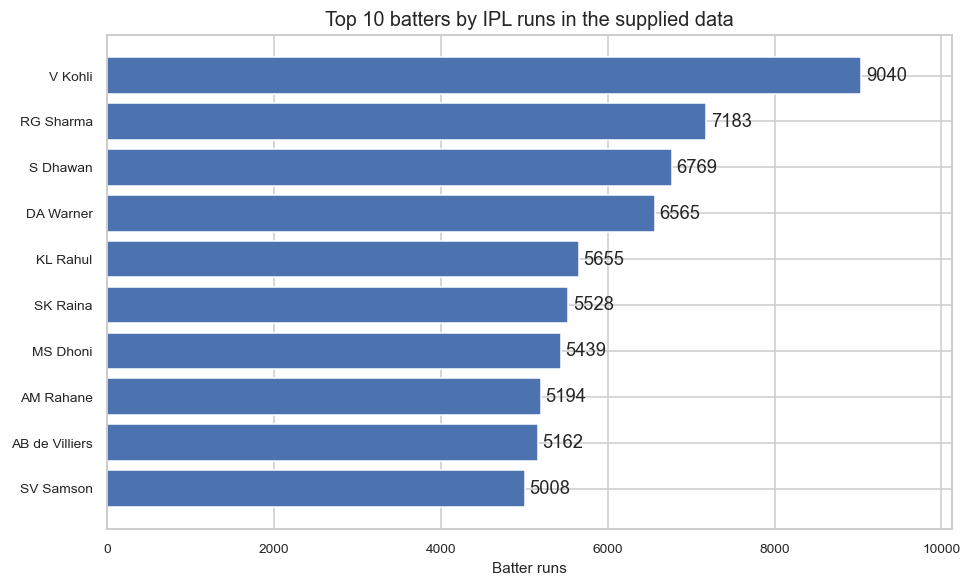

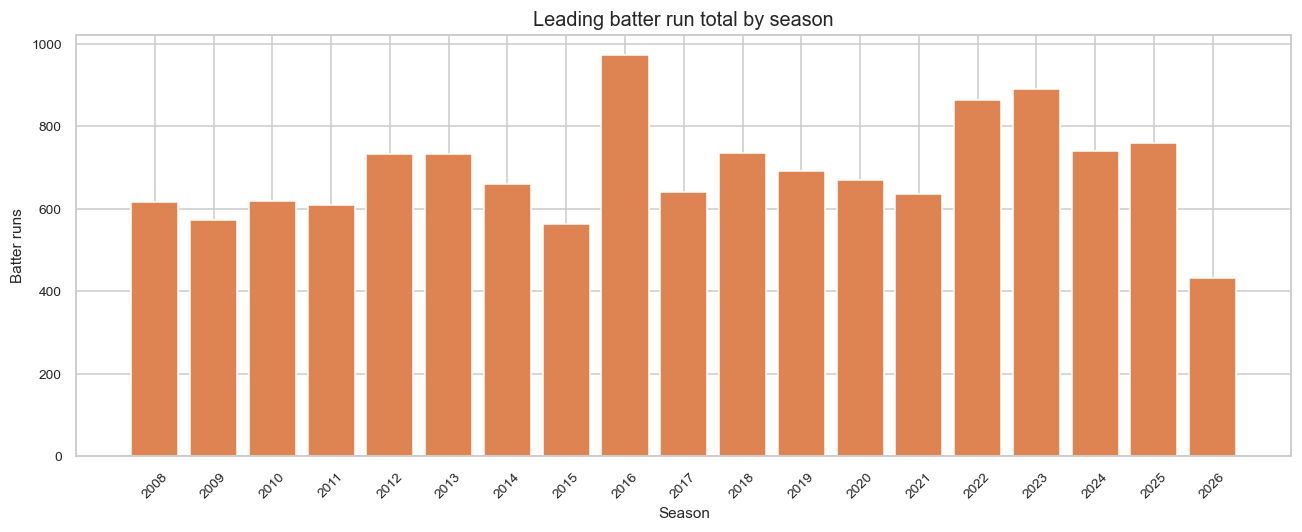

Highest overall run totals with strike-rate context:


,batter,total_runs,balls_faced,strike_rate
682,V Kohli,9040,6748,133.965619
521,RG Sharma,7183,5417,132.601071
557,S Dhawan,6769,5324,127.141247
157,DA Warner,6565,4697,139.770066
308,KL Rahul,5655,4072,138.875246
591,SK Raina,5528,4043,136.730151
406,MS Dhoni,5439,3957,137.452616
51,AM Rahane,5194,4145,125.307600
31,AB de Villiers,5162,3403,151.689686
619,SV Samson,5008,3562,140.595171


In [6]:
regulation = df.loc[~df["is_super_over"]].copy()

batter_innings = (
    regulation.groupby(["season_id", "match_id", "innings", "batter"], as_index=False)
    .agg(
        total_runs=("batter_runs", "sum"),
        balls_faced=("is_batter_ball_faced", "sum"),
        fours=("is_boundary_four", "sum"),
        sixes=("is_six", "sum"),
    )
)
batting_stats = (
    batter_innings.groupby(["season_id", "batter"], as_index=False)
    .agg(
        total_runs=("total_runs", "sum"),
        innings=("match_id", "size"),
        balls_faced=("balls_faced", "sum"),
        fours=("fours", "sum"),
        sixes=("sixes", "sum"),
    )
)
dismissals = (
    regulation.loc[
        regulation["is_wicket_lost"] & regulation["player_out"].notna(),
        ["season_id", "player_out"],
    ]
    .groupby(["season_id", "player_out"])
    .size()
    .rename("dismissals")
    .reset_index()
    .rename(columns={"player_out": "batter"})
)
batting_stats = batting_stats.merge(dismissals, on=["season_id", "batter"], how="left", validate="one_to_one")
batting_stats["dismissals"] = batting_stats["dismissals"].fillna(0).astype("int64")
batting_stats["strike_rate"] = np.divide(
    batting_stats["total_runs"] * 100,
    batting_stats["balls_faced"],
    out=np.full(len(batting_stats), np.nan, dtype=float),
    where=batting_stats["balls_faced"].to_numpy() > 0,
)

overall_batting = (
    batting_stats.groupby("batter", as_index=False)
    .agg(
        total_runs=("total_runs", "sum"),
        innings=("innings", "sum"),
        balls_faced=("balls_faced", "sum"),
        fours=("fours", "sum"),
        sixes=("sixes", "sum"),
        dismissals=("dismissals", "sum"),
    )
)
overall_batting["strike_rate"] = np.divide(
    overall_batting["total_runs"] * 100,
    overall_batting["balls_faced"],
    out=np.full(len(overall_batting), np.nan, dtype=float),
    where=overall_batting["balls_faced"].to_numpy() > 0,
)


def season_leaders(frame, metric):
    maxima = frame.groupby("season_id")[metric].transform("max")
    return (
        frame.loc[frame[metric].eq(maxima)]
        .sort_values(["season_id", metric], ascending=[True, False])
        .reset_index(drop=True)
    )


run_leaders = season_leaders(batting_stats, "total_runs")
six_leaders = season_leaders(batting_stats, "sixes")
four_leaders = season_leaders(batting_stats, "fours")

fifty_delivery_rows = regulation.sort_values(
    ["season_id", "match_id", "innings", "over_number", "ball_number"], kind="stable"
).copy()
fifty_groups = ["season_id", "match_id", "innings", "batter"]
fifty_delivery_rows["cumulative_batter_runs"] = (
    fifty_delivery_rows.groupby(fifty_groups, sort=False)["batter_runs"].cumsum()
)
fifty_delivery_rows["cumulative_batter_balls_faced"] = (
    fifty_delivery_rows.groupby(fifty_groups, sort=False)["is_batter_ball_faced"].cumsum()
)
fastest_fifties = (
    fifty_delivery_rows.loc[fifty_delivery_rows["cumulative_batter_runs"].ge(50)]
    .groupby(fifty_groups, as_index=False, sort=False)
    .first()
    .rename(columns={"cumulative_batter_balls_faced": "balls_to_50"})
)
fastest_fifties = fastest_fifties[
    ["season_id", "match_id", "innings", "batter", "balls_to_50", "cumulative_batter_runs"]
]
fastest_fifties["balls_to_50"] = fastest_fifties["balls_to_50"].astype("int64")
season_fastest_fifties = season_leaders(
    fastest_fifties.assign(_fastest_metric=-fastest_fifties["balls_to_50"]), "_fastest_metric"
).drop(columns="_fastest_metric")

if int(batting_stats["total_runs"].sum()) != int(regulation["batter_runs"].sum()):
    raise ValueError("Season batting totals do not reconcile with regulation delivery runs.")
if not np.isfinite(batting_stats["strike_rate"].dropna()).all():
    raise ValueError("Batting strike rate contains an infinite or invalid value.")
add_check("season_batter_runs_reconcile", True, int(batting_stats["total_runs"].sum()),
          int(regulation["batter_runs"].sum()))
add_check("batting_strike_rates_finite", True, "finite or null", "no infinities")

print("Leading run-scorer(s) per observed season (ties retained):")
display(run_leaders[["season_id", "batter", "total_runs", "innings", "balls_faced", "strike_rate"]])
print("Season leaders in sixes and fours (ties retained):")
display(six_leaders[["season_id", "batter", "sixes"]])
display(four_leaders[["season_id", "batter", "fours"]])
print("Fastest fifties per observed season (ties retained):")
display(season_fastest_fifties)

top_batters = overall_batting.nlargest(10, "total_runs").sort_values("total_runs")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top_batters["batter"], top_batters["total_runs"], color=sns.color_palette("deep")[0])
ax.set(title="Top 10 batters by IPL runs in the supplied data", xlabel="Batter runs", ylabel="")
ax.bar_label(ax.containers[0], fmt="%d", padding=3)
ax.margins(x=0.12)
plt.tight_layout()
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(run_leaders["season_id"].astype(int), run_leaders["total_runs"], color=sns.color_palette("deep")[1])
ax.set(title="Leading batter run total by season", xlabel="Season", ylabel="Batter runs")
ax.set_xticks(season_coverage)
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
plt.close(fig)

print("Highest overall run totals with strike-rate context:")
display(overall_batting.nlargest(10, "total_runs")[["batter", "total_runs", "balls_faced", "strike_rate"]])


## Bowling analysis

Bowling statistics aggregate regulation deliveries. Economy is runs conceded per six legal balls; bowling average is runs conceded per bowler-creditable wicket; bowling strike rate is legal balls per bowler-creditable wicket. Zero-denominator metrics remain missing. Economy rankings have no minimum-balls cutoff, so low-volume entries must be interpreted cautiously.


Leading wicket-taker(s) by season:


,season_id,bowler,wickets,legal_balls,economy_rate
0,2008,Sohail Tanvir,22,247,6.461538
1,2009,RP Singh,23,358,6.988827
2,2010,PP Ojha,21,353,7.291785
3,2011,SL Malinga,28,378,5.952381
4,2012,M Morkel,25,378,7.190476
5,2013,DJ Bravo,32,375,7.952000
6,2014,MM Sharma,23,323,8.396285
7,2015,DJ Bravo,26,314,8.140127
8,2016,B Kumar,23,396,7.424242
9,2017,B Kumar,26,314,7.050955


Season leaders in dot-ball count and percentage:


,season_id,bowler,dot_balls,legal_balls
0,2008,SR Watson,158,325
1,2009,RP Singh,169,358
2,2010,DW Steyn,164,354
3,2011,SL Malinga,183,378
4,2012,P Kumar,168,378
5,2013,DW Steyn,211,407
6,2014,AR Patel,157,396
7,2014,SP Narine,157,384
8,2015,A Nehra,170,372
9,2016,B Kumar,156,396


,season_id,bowler,dot_ball_percentage,legal_balls
0,2008,Shoaib Akhtar,54.761905,42
1,2009,CK Langeveldt,66.666667,24
2,2009,LA Carseldine,66.666667,6
3,2010,ND Doshi,58.333333,24
4,2011,SS Mundhe,66.666667,6
5,2012,BW Hilfenhaus,50.490196,204
6,2013,AC Gilchrist,100.000000,1
7,2014,M Morkel,51.388889,288
8,2015,M de Lange,62.500000,24
9,2016,JW Hastings,55.000000,40


Lowest economy rate per season; no minimum-ball eligibility cutoff:


,season_id,bowler,economy_rate,legal_balls
85,2008,TM Dilshan,3.000000,6
166,2009,R Ashwin,3.250000,24
322,2010,V Sehwag,4.058824,34
436,2011,S Rana,3.000000,4
533,2012,L Balaji,5.400000,180
605,2013,AC Gilchrist,0.000000,1
733,2014,Ankit Sharma,5.375000,48
903,2015,RN ten Doeschate,4.000000,6
992,2016,N Rana,3.000000,6
1098,2017,NB Singh,3.750000,24


Bowler-creditable dismissal breakdown:


,wicket_kind,bowler_creditable_wickets
0,caught,9045
1,bowled,2398
2,lbw,871
3,caught and bowled,399
4,stumped,382
5,hit wicket,18


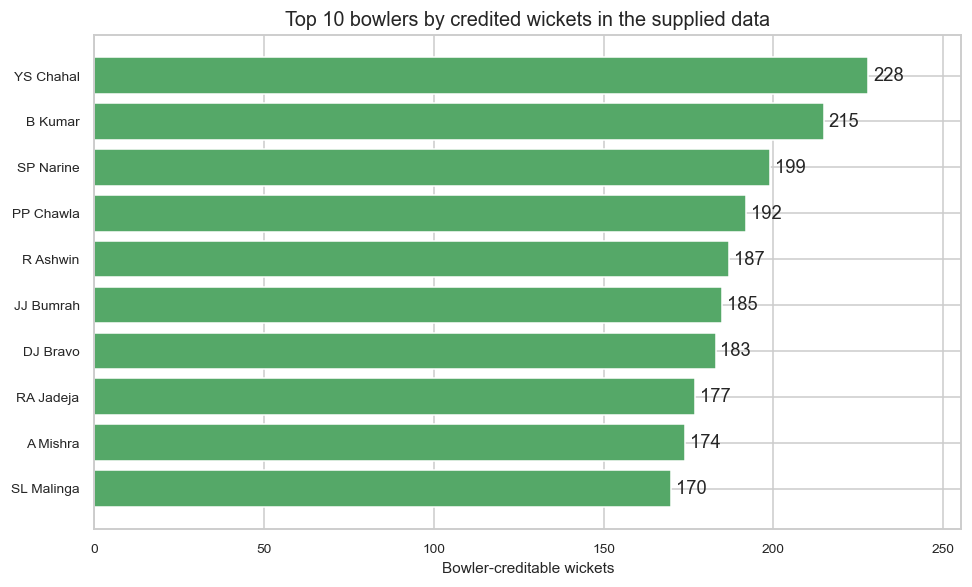

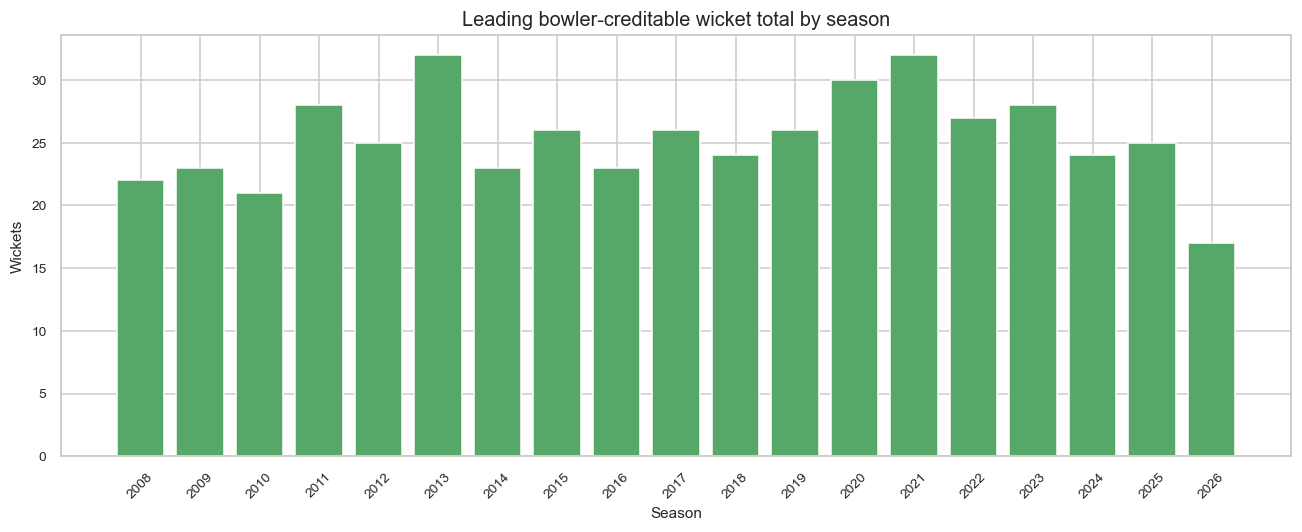

In [7]:
bowler_innings = (
    regulation.groupby(["season_id", "match_id", "innings", "bowler"], as_index=False)
    .agg(
        runs_conceded=("bowler_runs_conceded", "sum"),
        legal_balls=("is_legal_delivery", "sum"),
        wickets=("bowler_wickets", "sum"),
        dot_balls=("is_dot_ball", "sum"),
    )
)
bowling_stats = (
    bowler_innings.groupby(["season_id", "bowler"], as_index=False)
    .agg(
        runs_conceded=("runs_conceded", "sum"),
        legal_balls=("legal_balls", "sum"),
        wickets=("wickets", "sum"),
        dot_balls=("dot_balls", "sum"),
        innings_bowled=("match_id", "size"),
    )
)
bowling_stats["overs_bowled"] = bowling_stats["legal_balls"] / 6
bowling_stats["economy_rate"] = np.divide(
    bowling_stats["runs_conceded"] * 6,
    bowling_stats["legal_balls"],
    out=np.full(len(bowling_stats), np.nan, dtype=float),
    where=bowling_stats["legal_balls"].to_numpy() > 0,
)
bowling_stats["bowling_average"] = np.divide(
    bowling_stats["runs_conceded"],
    bowling_stats["wickets"],
    out=np.full(len(bowling_stats), np.nan, dtype=float),
    where=bowling_stats["wickets"].to_numpy() > 0,
)
bowling_stats["bowling_strike_rate"] = np.divide(
    bowling_stats["legal_balls"],
    bowling_stats["wickets"],
    out=np.full(len(bowling_stats), np.nan, dtype=float),
    where=bowling_stats["wickets"].to_numpy() > 0,
)
bowling_stats["dot_ball_percentage"] = np.divide(
    bowling_stats["dot_balls"] * 100,
    bowling_stats["legal_balls"],
    out=np.full(len(bowling_stats), np.nan, dtype=float),
    where=bowling_stats["legal_balls"].to_numpy() > 0,
)
overall_bowling = (
    bowling_stats.groupby("bowler", as_index=False)
    .agg(
        runs_conceded=("runs_conceded", "sum"),
        legal_balls=("legal_balls", "sum"),
        wickets=("wickets", "sum"),
        dot_balls=("dot_balls", "sum"),
        innings_bowled=("innings_bowled", "sum"),
    )
)
overall_bowling["economy_rate"] = np.divide(
    overall_bowling["runs_conceded"] * 6,
    overall_bowling["legal_balls"],
    out=np.full(len(overall_bowling), np.nan, dtype=float),
    where=overall_bowling["legal_balls"].to_numpy() > 0,
)
overall_bowling["bowling_average"] = np.divide(
    overall_bowling["runs_conceded"],
    overall_bowling["wickets"],
    out=np.full(len(overall_bowling), np.nan, dtype=float),
    where=overall_bowling["wickets"].to_numpy() > 0,
)
overall_bowling["bowling_strike_rate"] = np.divide(
    overall_bowling["legal_balls"],
    overall_bowling["wickets"],
    out=np.full(len(overall_bowling), np.nan, dtype=float),
    where=overall_bowling["wickets"].to_numpy() > 0,
)
overall_bowling["dot_ball_percentage"] = np.divide(
    overall_bowling["dot_balls"] * 100,
    overall_bowling["legal_balls"],
    out=np.full(len(overall_bowling), np.nan, dtype=float),
    where=overall_bowling["legal_balls"].to_numpy() > 0,
)

season_wicket_leaders = season_leaders(bowling_stats, "wickets")
season_dot_leaders = season_leaders(bowling_stats, "dot_balls")
season_dot_pct_leaders = season_leaders(bowling_stats, "dot_ball_percentage")
economy_eligible = bowling_stats.loc[bowling_stats["economy_rate"].notna()].copy()
season_min_economy = economy_eligible.groupby("season_id")["economy_rate"].transform("min")
season_economy_leaders = economy_eligible.loc[
    economy_eligible["economy_rate"].eq(season_min_economy)
].sort_values(["season_id", "bowler"])
dismissal_breakdown = (
    regulation.loc[regulation["bowler_wickets"]]
    .groupby("wicket_kind")
    .size()
    .sort_values(ascending=False)
    .rename("bowler_creditable_wickets")
    .rename_axis("wicket_kind")
    .reset_index()
)

if int(bowling_stats["wickets"].sum()) != int(regulation["bowler_wickets"].sum()):
    raise ValueError("Season bowler wickets do not reconcile with delivery-level creditable wickets.")
if not np.isfinite(bowling_stats["economy_rate"].dropna()).all():
    raise ValueError("Bowling economy contains an infinite or invalid value.")
add_check("bowler_wickets_reconcile", True, int(bowling_stats["wickets"].sum()),
          int(regulation["bowler_wickets"].sum()))
add_check("bowling_rates_finite", True, "finite or null", "no infinities")

print("Leading wicket-taker(s) by season:")
display(season_wicket_leaders[["season_id", "bowler", "wickets", "legal_balls", "economy_rate"]])
print("Season leaders in dot-ball count and percentage:")
display(season_dot_leaders[["season_id", "bowler", "dot_balls", "legal_balls"]])
display(season_dot_pct_leaders[["season_id", "bowler", "dot_ball_percentage", "legal_balls"]])
print("Lowest economy rate per season; no minimum-ball eligibility cutoff:")
display(season_economy_leaders[["season_id", "bowler", "economy_rate", "legal_balls"]])
print("Bowler-creditable dismissal breakdown:")
display(dismissal_breakdown)

top_bowlers = overall_bowling.nlargest(10, "wickets").sort_values("wickets")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top_bowlers["bowler"], top_bowlers["wickets"], color=sns.color_palette("deep")[2])
ax.set(title="Top 10 bowlers by credited wickets in the supplied data", xlabel="Bowler-creditable wickets", ylabel="")
ax.bar_label(ax.containers[0], fmt="%d", padding=3)
ax.margins(x=0.12)
plt.tight_layout()
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(season_wicket_leaders["season_id"].astype(int), season_wicket_leaders["wickets"],
       color=sns.color_palette("deep")[2])
ax.set(title="Leading bowler-creditable wicket total by season", xlabel="Season", ylabel="Wickets")
ax.set_xticks(season_coverage)
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
plt.close(fig)


## Team and scoring analysis

Team results are grouped by the numeric batting-team ID because canonical names are unverified. Only regulation innings are included in team-season summaries and the following scoring charts. Innings scores are actual runs, not targets.


Team scoring and innings summary by season (team IDs retained):


,season_id,team_batting_id,innings,total_runs,total_legal_balls,total_wickets_lost,total_extras,fours,sixes,boundaries,boundary_runs,average_innings_score,run_rate
0,2008,1,14,1983,1601,106,118,187,59,246,1102,141.642857,7.431605
1,2008,2,14,2229,1613,93,112,205,92,297,1372,159.214286,8.291383
2,2008,3,14,2080,1495,79,183,197,76,273,1244,148.571429,8.347826
3,2008,6,13,1942,1495,88,141,162,76,238,1104,149.384615,7.793980
4,2008,129,16,2520,1789,79,155,244,86,330,1492,157.500000,8.451649
5,2008,134,16,2601,1784,88,177,259,85,344,1546,162.562500,8.747758
6,2008,252,14,2118,1495,77,118,218,54,272,1196,151.285714,8.500334
7,2008,494,15,2464,1678,79,124,231,95,326,1494,164.266667,8.810489
8,2009,1,16,2280,1861,106,114,192,67,259,1170,142.500000,7.350887
9,2009,2,16,2408,1828,101,125,173,99,272,1286,150.500000,7.903720


Average innings scores and run rates by season:


,season_id,average_innings_score,total_runs,total_legal_balls,innings,average_run_rate
0,2008,154.629310,17937,12950,116,8.310579
1,2009,143.157895,16320,13085,114,7.483378
2,2010,157.200000,18864,13929,120,8.125781
3,2011,145.889655,21154,16425,145,7.727489
4,2012,151.709459,22453,17208,148,7.828801
5,2013,148.296053,22541,17613,152,7.678760
6,2014,157.575000,18909,13833,120,8.201692
7,2015,156.683761,18332,13141,117,8.370139
8,2016,157.183333,18862,13618,120,8.310471
9,2017,159.059322,18769,13390,118,8.410306


Powerplay, middle-over, and death-over runs:


...

,season_id,match_id,innings,team_batting_id,total_runs,wickets_lost
1033,2015,829813,2,1,2,0
2306,2025,1473481,2,6,7,0
2387,2026,1527685,1,6,25,2
1503,2019,1178424,2,134,41,1
868,2014,733993,2,2,44,2
2105,2024,1422134,1,6,272,7
2089,2024,1422126,1,2,277,3
2349,2025,1473505,1,2,278,3
2219,2025,1473439,1,2,286,6
2133,2024,1426268,1,2,287,3


Boundary contribution:


,season_id,total_runs,boundary_runs,other_runs
0,2008,17937,10550,7387
1,2009,16320,8304,8016
2,2010,18864,10342,8522
3,2011,21154,11498,9656
4,2012,22453,12042,10411
5,2013,22541,12258,10283
6,2014,18909,10532,8377
7,2015,18332,10580,7752
8,2016,18862,10366,8496
9,2017,18769,10674,8095


Extras distribution:


,extra_type,runs
0,Wides,11389
2,Leg-byes,5658
3,Byes,1356
1,No-balls,1228
4,Penalty,10


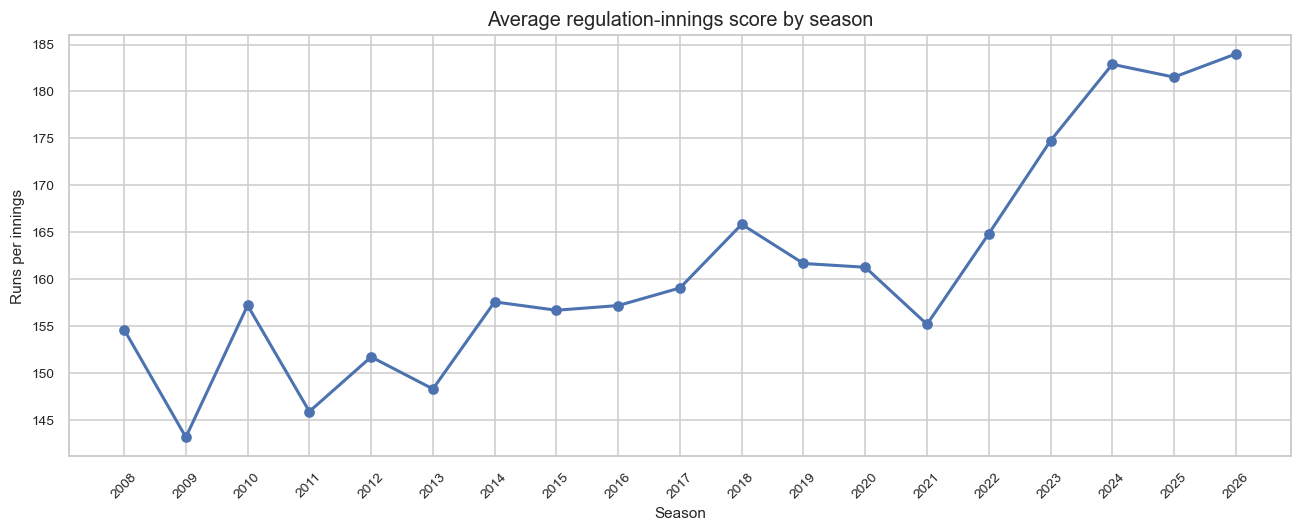

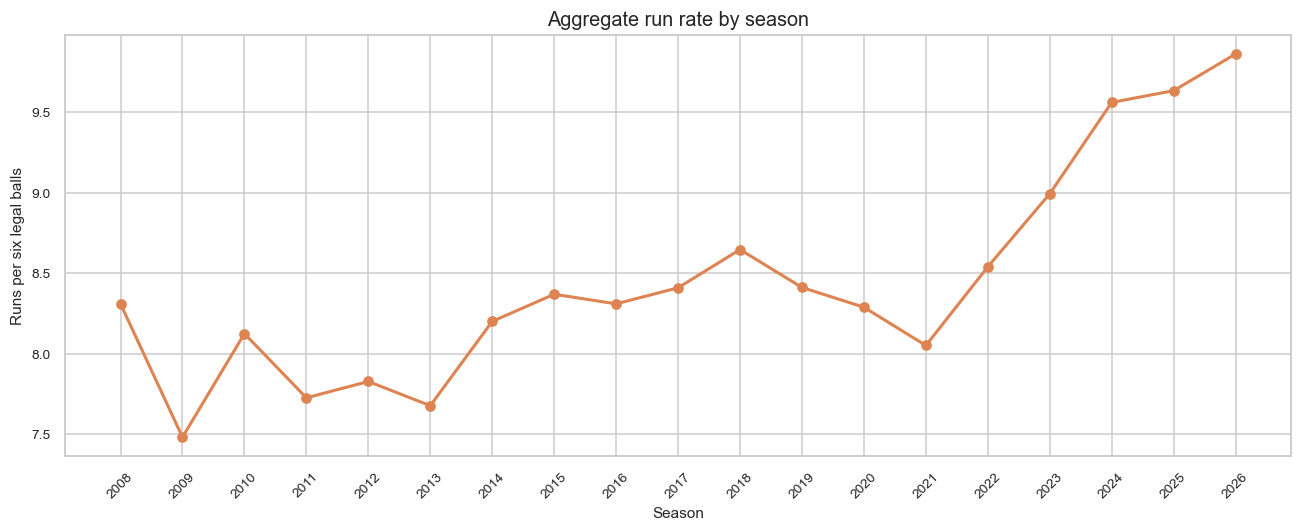

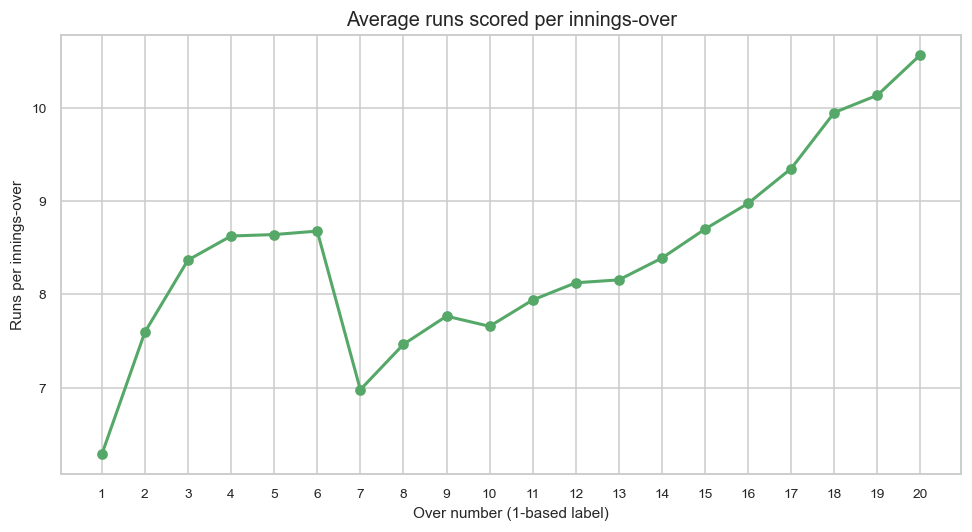

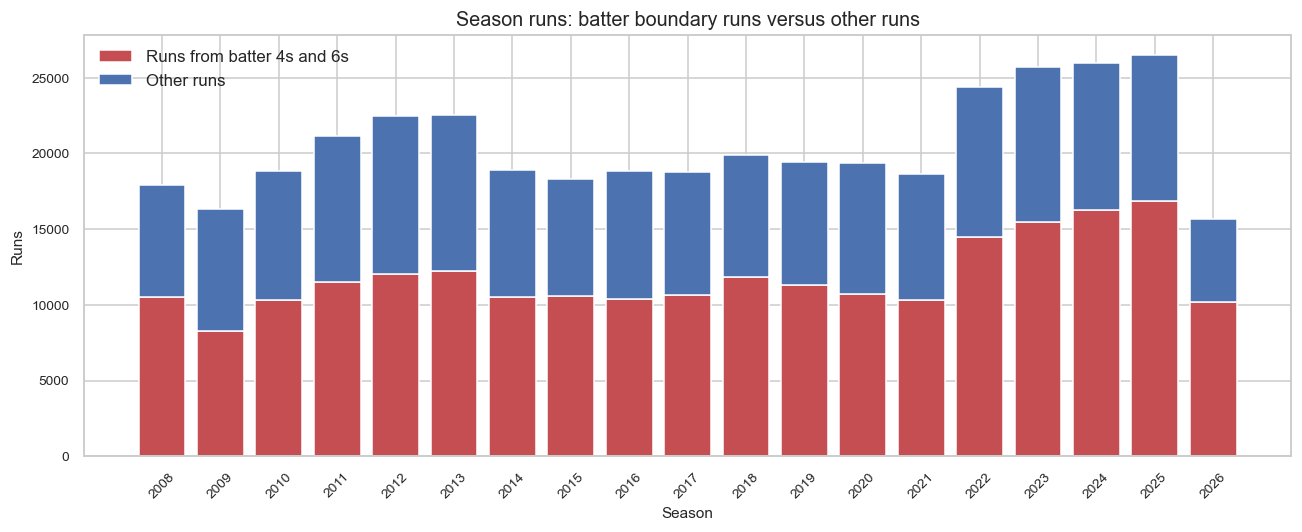

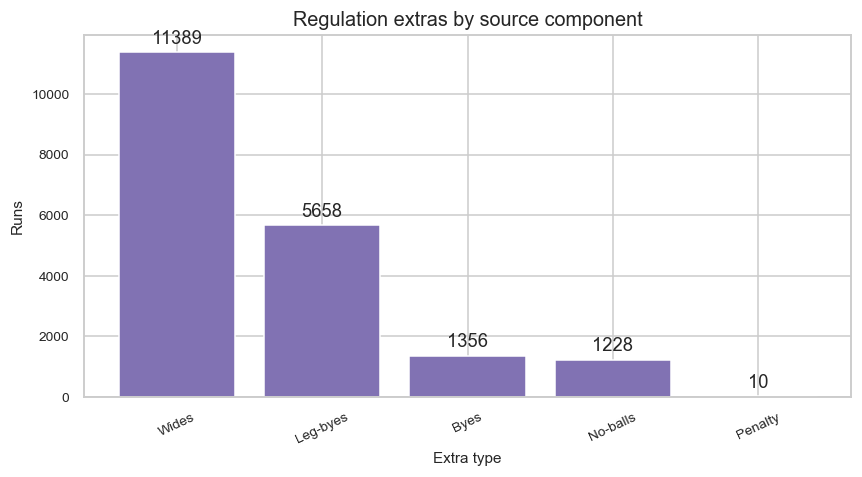

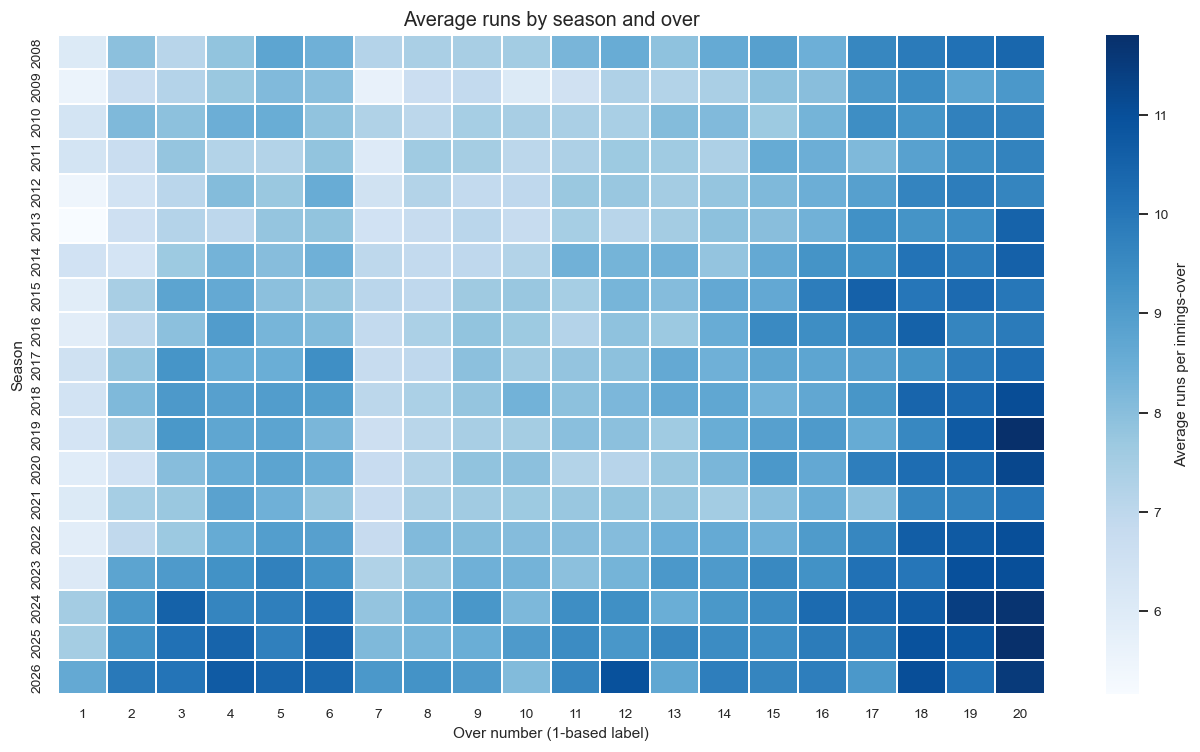

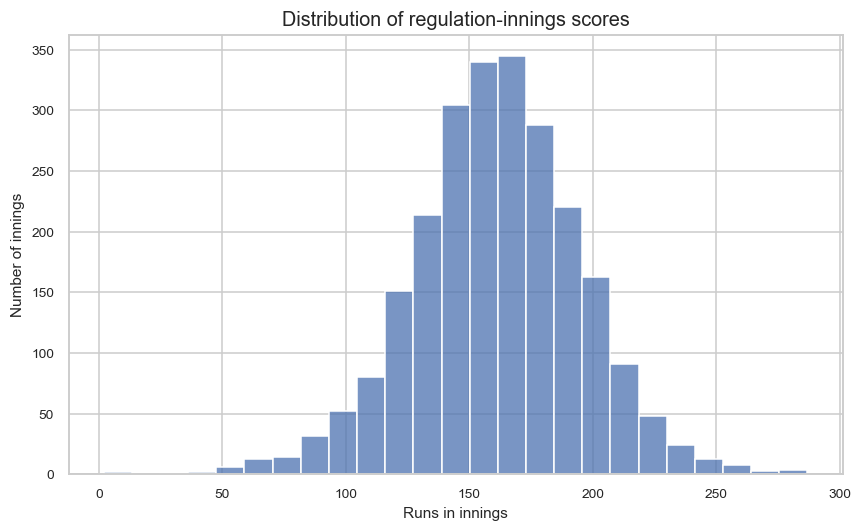

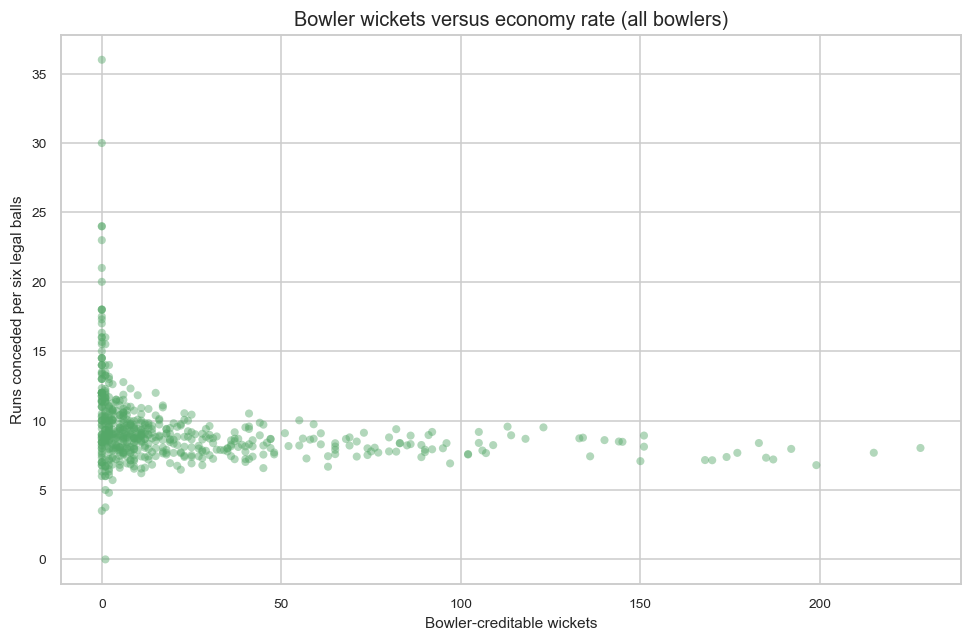

In [8]:
team_season_stats = (
    summary.loc[~summary["is_super_over"]]
    .groupby(["season_id", "team_batting_id"], as_index=False)
    .agg(
        innings=("match_id", "size"),
        total_runs=("total_runs", "sum"),
        total_legal_balls=("legal_balls", "sum"),
        total_wickets_lost=("wickets_lost", "sum"),
        total_extras=("extras", "sum"),
        fours=("fours", "sum"),
        sixes=("sixes", "sum"),
        boundaries=("boundary_count", "sum"),
        boundary_runs=("boundary_runs", "sum"),
        average_innings_score=("total_runs", "mean"),
    )
)
team_season_stats["run_rate"] = np.divide(
    team_season_stats["total_runs"] * 6,
    team_season_stats["total_legal_balls"],
    out=np.full(len(team_season_stats), np.nan, dtype=float),
    where=team_season_stats["total_legal_balls"].to_numpy() > 0,
)

regular_innings = summary.loc[~summary["is_super_over"]].copy()
season_scoring = (
    regular_innings.groupby("season_id", as_index=False)
    .agg(
        average_innings_score=("total_runs", "mean"),
        total_runs=("total_runs", "sum"),
        total_legal_balls=("legal_balls", "sum"),
        innings=("match_id", "size"),
    )
)
season_scoring["average_run_rate"] = np.divide(
    season_scoring["total_runs"] * 6,
    season_scoring["total_legal_balls"],
    out=np.full(len(season_scoring), np.nan, dtype=float),
    where=season_scoring["total_legal_balls"].to_numpy() > 0,
)

phase_summary = (
    regular_innings.melt(
        id_vars=["season_id", "match_id", "innings"],
        value_vars=["powerplay_runs", "middle_over_runs", "death_over_runs"],
        var_name="phase",
        value_name="phase_runs",
    )
    .groupby("phase", as_index=False)
    .agg(average_runs_per_innings=("phase_runs", "mean"), total_runs=("phase_runs", "sum"))
)
phase_summary["phase"] = phase_summary["phase"].str.replace("_runs", "", regex=False)

regular_delivery_rows = regulation.copy()
over_scores_by_innings = (
    regular_delivery_rows.groupby(
        ["season_id", "match_id", "innings", "over_number"], as_index=False
    )
    .agg(runs_in_over=("total_runs", "sum"))
)
runs_by_over = (
    over_scores_by_innings.groupby("over_number", as_index=False)
    .agg(
        total_runs=("runs_in_over", "sum"),
        average_runs_per_innings_over=("runs_in_over", "mean"),
        innings_over_observations=("runs_in_over", "size"),
    )
    .sort_values("over_number")
)
season_over_heatmap = (
    over_scores_by_innings.groupby(["season_id", "over_number"])["runs_in_over"]
    .mean()
    .unstack("over_number")
    .reindex(index=season_coverage, columns=range(20))
)
boundary_by_season = (
    regular_innings.groupby("season_id", as_index=False)
    .agg(total_runs=("total_runs", "sum"), boundary_runs=("boundary_runs", "sum"))
)
boundary_by_season["other_runs"] = boundary_by_season["total_runs"] - boundary_by_season["boundary_runs"]

extra_names = {
    "wide_ball_runs": "Wides",
    "no_ball_runs": "No-balls",
    "leg_bye_runs": "Leg-byes",
    "bye_runs": "Byes",
    "penalty_runs": "Penalty",
}
extras_by_type = (
    regulation[list(extra_names)]
    .sum()
    .rename(index=extra_names)
    .rename("runs")
    .rename_axis("extra_type")
    .reset_index()
    .sort_values("runs", ascending=False)
)

print("Team scoring and innings summary by season (team IDs retained):")
display(team_season_stats.head(20))
print("Average innings scores and run rates by season:")
display(season_scoring)
print("Powerplay, middle-over, and death-over runs:")
display(phase_summary)
print("Highest and lowest actual regulation-innings scores:")
display(pd.concat([regular_innings.nsmallest(5, "total_runs"), regular_innings.nlargest(5, "total_runs")])
        [["season_id", "match_id", "innings", "team_batting_id", "total_runs", "wickets_lost"]]
        .sort_values(["total_runs", "season_id"]))
print("Boundary contribution:")
display(boundary_by_season)
print("Extras distribution:")
display(extras_by_type)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(season_scoring["season_id"], season_scoring["average_innings_score"],
        marker="o", linewidth=2, color=sns.color_palette("deep")[0])
ax.set(title="Average regulation-innings score by season", xlabel="Season", ylabel="Runs per innings")
ax.set_xticks(season_coverage)
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(season_scoring["season_id"], season_scoring["average_run_rate"],
        marker="o", linewidth=2, color=sns.color_palette("deep")[1])
ax.set(title="Aggregate run rate by season", xlabel="Season", ylabel="Runs per six legal balls")
ax.set_xticks(season_coverage)
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(runs_by_over["over_number"] + 1, runs_by_over["average_runs_per_innings_over"],
        marker="o", linewidth=2, color=sns.color_palette("deep")[2])
ax.set(title="Average runs scored per innings-over", xlabel="Over number (1-based label)", ylabel="Runs per innings-over")
ax.set_xticks(range(1, 21))
plt.tight_layout()
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(boundary_by_season["season_id"], boundary_by_season["boundary_runs"],
       label="Runs from batter 4s and 6s", color=sns.color_palette("deep")[3])
ax.bar(boundary_by_season["season_id"], boundary_by_season["other_runs"],
       bottom=boundary_by_season["boundary_runs"], label="Other runs", color=sns.color_palette("deep")[0])
ax.set(title="Season runs: batter boundary runs versus other runs", xlabel="Season", ylabel="Runs")
ax.set_xticks(season_coverage)
ax.tick_params(axis="x", rotation=45)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(extras_by_type["extra_type"], extras_by_type["runs"], color=sns.color_palette("deep")[4])
ax.set(title="Regulation extras by source component", xlabel="Extra type", ylabel="Runs")
ax.tick_params(axis="x", rotation=25)
ax.bar_label(ax.containers[0], fmt="%d", padding=3)
plt.tight_layout()
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(season_over_heatmap, cmap="Blues", linewidths=0.15,
            cbar_kws={"label": "Average runs per innings-over"}, ax=ax)
ax.set(title="Average runs by season and over", xlabel="Over number (1-based label)", ylabel="Season")
ax.set_xticks(np.arange(20) + 0.5)
ax.set_xticklabels(range(1, 21))
plt.tight_layout()
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(regular_innings["total_runs"], bins=25, color=sns.color_palette("deep")[0], ax=ax)
ax.set(title="Distribution of regulation-innings scores", xlabel="Runs in innings", ylabel="Number of innings")
plt.tight_layout()
plt.show()
plt.close(fig)

scatter_data = overall_bowling.loc[overall_bowling["legal_balls"].gt(0)].copy()
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(scatter_data["wickets"], scatter_data["economy_rate"], alpha=0.45, s=28,
           color=sns.color_palette("deep")[2], edgecolors="none")
ax.set(title="Bowler wickets versus economy rate (all bowlers)",
       xlabel="Bowler-creditable wickets", ylabel="Runs conceded per six legal balls")
plt.tight_layout()
plt.show()
plt.close(fig)


## Match outcomes, venues, and interpretation

The source contains no genuine match-level result, date, venue, toss, or champion fields. An ESPN API metadata lookup and GitHub source search did not return a validated match-level table covering these source IDs and seasons. No join is performed, and no match-result table is exported.

Historical team-name aliases are also not inferred from the prior notebook's dictionary. The export keeps team IDs and records all unresolved IDs in `unmapped_team_ids.csv`.


In [9]:
top_scorer = overall_batting.sort_values(["total_runs", "batter"], ascending=[False, True]).iloc[0]
top_wicket_taker = overall_bowling.sort_values(["wickets", "bowler"], ascending=[False, True]).iloc[0]
highest_average_score = season_scoring.sort_values("average_innings_score", ascending=False).iloc[0]
fastest_fifty_observed = (
    fastest_fifties.sort_values(["balls_to_50", "season_id", "batter"])
    .iloc[0]
    if not fastest_fifties.empty
    else None
)
matches_by_season = df.groupby("season_id")["match_id"].nunique()

print(
    f"Across the supplied file, {top_scorer['batter']} has the most regulation runs "
    f"({int(top_scorer['total_runs']):,}); {top_wicket_taker['bowler']} has the most "
    f"bowler-creditable regulation wickets ({int(top_wicket_taker['wickets']):,})."
)
print(
    f"The highest average regulation-innings score among observed seasons is "
    f"{highest_average_score['average_innings_score']:.1f} in {int(highest_average_score['season_id'])}."
)
if fastest_fifty_observed is not None:
    print(
        f"Fastest observed fifty: {fastest_fifty_observed['batter']} in "
        f"{int(fastest_fifty_observed['season_id'])}, reaching 50 in "
        f"{int(fastest_fifty_observed['balls_to_50'])} balls faced."
    )
else:
    print("No batter reached 50 runs in the available regulation deliveries.")
print(
    "Observed season coverage and matches per season (coverage does not prove completeness): "
    f"{matches_by_season.to_dict()}"
)


Across the supplied file, V Kohli has the most regulation runs (9,040); YS Chahal has the most bowler-creditable regulation wickets (228).
The highest average regulation-innings score among observed seasons is 184.0 in 2026.
Fastest observed fifty: YBK Jaiswal in 2023, reaching 50 in 13 balls faced.
Observed season coverage and matches per season (coverage does not prove completeness): {2008: 58, 2009: 57, 2010: 60, 2011: 73, 2012: 74, 2013: 76, 2014: 60, 2015: 59, 2016: 60, 2017: 59, 2018: 60, 2019: 60, 2020: 60, 2021: 60, 2022: 74, 2023: 74, 2024: 71, 2025: 74, 2026: 43}


## Validation, Power BI exports, and data dictionary

All export keys and metric denominators are checked before writing files. Outputs are UTF-8 CSVs in `outputs/powerbi/`. Match metadata is intentionally omitted because no validated source was available.


In [10]:
# Verify delivery-derived flags and output grain before writing any files.
feature_failures = {
    "legal_delivery": int((df["is_legal_delivery"] != ~(df["is_wide_ball"] | df["is_no_ball"])).sum()),
    "dot_ball": int((df["is_dot_ball"] != (df["is_legal_delivery"] & df["total_runs"].eq(0))).sum()),
    "bowler_runs_reconciliation": int(
        (df["bowler_runs_conceded"] + df["bye_runs"] + df["leg_bye_runs"] + df["penalty_runs"]
         != df["total_runs"]).sum()
    ),
}
add_check("delivery_feature_reconciliation", sum(feature_failures.values()) == 0,
          feature_failures, "all zero")
add_check("unique_batting_season_key", not batting_stats.duplicated(["season_id", "batter"]).any(),
          int(batting_stats.duplicated(["season_id", "batter"]).sum()), 0)
add_check("unique_bowling_season_key", not bowling_stats.duplicated(["season_id", "bowler"]).any(),
          int(bowling_stats.duplicated(["season_id", "bowler"]).sum()), 0)
add_check("unique_team_season_key",
          not team_season_stats.duplicated(["season_id", "team_batting_id"]).any(),
          int(team_season_stats.duplicated(["season_id", "team_batting_id"]).sum()), 0)
add_check("finite_exported_rates",
          all(
              np.isfinite(table[column].dropna()).all()
              for table, columns in [
                  (summary, ["run_rate", "overs_faced"]),
                  (batting_stats, ["strike_rate"]),
                  (bowling_stats, ["economy_rate", "bowling_average", "bowling_strike_rate", "dot_ball_percentage"]),
                  (team_season_stats, ["run_rate", "average_innings_score"]),
              ]
              for column in columns
          ),
          "all rates finite or null", "no infinities or invalid denominator results")
add_check("metadata_join_row_multiplication", len(df) == source_row_count,
          len(df), source_row_count, "No metadata table was available or joined.")
add_check("match_metadata_availability", False, "not available", "verified match-level source",
          "Dates, venues, winners, and toss data are not exported.", info=True)

missingness = (
    raw_df.isna().sum()
    .rename("missing_rows")
    .rename_axis("column")
    .reset_index()
)
missingness["total_rows"] = len(raw_df)
missingness["missing_percent"] = (missingness["missing_rows"] / len(raw_df) * 100).round(4)
missing_reasons = {
    "player_out": "Expected missing on deliveries without a dismissal; consistency checked.",
    "wicket_kind": "Expected missing on deliveries without a dismissal; consistency checked.",
    "fielders_involved": "May be absent where no fielder is involved; source values preserved.",
    "batsman_type": "Optional source attribute; source missingness preserved.",
    "bowler_type": "Optional source attribute; source missingness preserved.",
}
missingness["interpretation"] = missingness["column"].map(missing_reasons).fillna(
    "Source missingness preserved; review according to field meaning."
)
for row in missingness.itertuples(index=False):
    add_check(
        f"missingness_{row.column}",
        True,
        f"{int(row.missing_rows)} / {int(row.total_rows)} ({row.missing_percent:.4f}%)",
        "reported; not imputed",
        row.interpretation,
        info=True,
    )

failed_checks = [check for check in quality_checks if check["status"] == "FAIL"]
if failed_checks:
    raise AssertionError(f"Data-quality validation failed: {failed_checks}")

quality_report = pd.DataFrame(quality_checks)
quality_report["source_path"] = DATA_PATH.name

# Power BI fact and dimension tables.
delivery_export_columns = original_columns + [
    "is_legal_delivery", "is_dot_ball", "is_boundary_four", "is_six",
    "bowler_wickets", "is_wicket_lost", "is_batter_ball_faced", "bowler_runs_conceded",
    "innings_phase", "cumulative_innings_runs", "cumulative_innings_wickets",
    "boundary_count", "boundary_runs",
]
delivery_export_columns = list(dict.fromkeys(delivery_export_columns))
deliveries_export = df[delivery_export_columns].copy()
innings_export_columns = [
    "season_id", "match_id", "innings", "is_super_over", "team_batting_id",
    "total_runs", "wickets_lost", "legal_balls", "overs_faced", "run_rate",
    "fours", "sixes", "boundary_count", "boundary_runs", "extras",
    "powerplay_runs", "middle_over_runs", "death_over_runs",
]
innings_export = summary[innings_export_columns].copy()
batting_export_columns = [
    "season_id", "batter", "total_runs", "innings", "balls_faced",
    "fours", "sixes", "dismissals", "strike_rate",
]
batting_export = batting_stats[batting_export_columns].copy()
bowling_export_columns = [
    "season_id", "bowler", "wickets", "legal_balls", "overs_bowled",
    "runs_conceded", "economy_rate", "bowling_average",
    "bowling_strike_rate", "dot_balls", "dot_ball_percentage",
]
bowling_export = bowling_stats[bowling_export_columns].copy()
team_export_columns = [
    "season_id", "team_batting_id", "innings", "total_runs", "total_legal_balls",
    "total_wickets_lost", "total_extras", "fours", "sixes", "boundaries",
    "boundary_runs", "average_innings_score", "run_rate",
]
team_export = team_season_stats[team_export_columns].copy()

dim_season = pd.DataFrame({"season_id": season_coverage, "season_label": season_coverage})
dim_team = team_audit[["team_id", "canonical_team_name", "mapping_status"]].copy()
dim_batter = pd.DataFrame({"batter": sorted(regulation["batter"].dropna().unique())})
dim_bowler = pd.DataFrame({"bowler": sorted(regulation["bowler"].dropna().unique())})

output_tables = {
    "ipl_deliveries_clean.csv": deliveries_export,
    "ipl_innings_summary.csv": innings_export,
    "ipl_batting_season_stats.csv": batting_export,
    "ipl_bowling_season_stats.csv": bowling_export,
    "ipl_team_season_stats.csv": team_export,
    "dim_season.csv": dim_season,
    "dim_team.csv": dim_team,
    "dim_batter.csv": dim_batter,
    "dim_bowler.csv": dim_bowler,
    "data_quality_report.csv": quality_report,
    "unmapped_team_ids.csv": team_audit,
}

output_keys = {
    "ipl_deliveries_clean.csv": delivery_key,
    "ipl_innings_summary.csv": summary_key,
    "ipl_batting_season_stats.csv": ["season_id", "batter"],
    "ipl_bowling_season_stats.csv": ["season_id", "bowler"],
    "ipl_team_season_stats.csv": ["season_id", "team_batting_id"],
    "dim_season.csv": ["season_id"],
    "dim_team.csv": ["team_id"],
    "dim_batter.csv": ["batter"],
    "dim_bowler.csv": ["bowler"],
    "unmapped_team_ids.csv": ["team_id"],
}
for filename, key in output_keys.items():
    duplicate_keys = int(output_tables[filename].duplicated(key).sum())
    add_check(f"unique_export_key_{filename}", duplicate_keys == 0, duplicate_keys, 0,
              f"Key: {key}")
    if duplicate_keys:
        raise AssertionError(f"{filename} contains {duplicate_keys} duplicate key rows.")

failed_checks = [check for check in quality_checks if check["status"] == "FAIL"]
if failed_checks:
    raise AssertionError(f"Output validation failed: {failed_checks}")
quality_report = pd.DataFrame(quality_checks)
quality_report["source_path"] = DATA_PATH.name
output_tables["data_quality_report.csv"] = quality_report

OUTPUT_DIR = Path.cwd() / "outputs" / "powerbi"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for filename, table in output_tables.items():
    table.to_csv(OUTPUT_DIR / filename, index=False, encoding="utf-8")

dictionary_sections = [
    "# Power BI export data dictionary",
    "",
    f"Source: `{DATA_PATH.name}` ({source_row_count:,} delivery rows).",
    "",
    "## Grain and scope",
    "",
    "- `ipl_deliveries_clean.csv`: one row per original delivery; source rows are not dropped.",
    "- `ipl_innings_summary.csv`: one row per season, match, innings, and super-over flag.",
    "- Batting and bowling tables: one row per season and batter/bowler, regulation innings only.",
    "- Team table: one row per season and numeric batting-team ID, regulation innings only.",
    "- Team names remain unmapped because no authoritative mapping was validated.",
    "- Match results, dates, venues, tosses, and title counts are omitted because no validated metadata source was available.",
    "",
    "## Definitions",
    "",
    "- `is_legal_delivery`: not a wide and not a no-ball.",
    "- `is_dot_ball`: legal delivery and zero total runs.",
    "- `is_batter_ball_faced`: all deliveries except wides; no-balls count as faced.",
    "- `bowler_wickets`: bowled, caught, caught and bowled, lbw, stumped, or hit wicket.",
    "- `is_wicket_lost`: source wicket except retired hurt.",
    "- `bowler_runs_conceded`: total runs less byes, leg-byes, and penalty runs.",
    "- `run_rate` / `economy_rate`: runs per six legal balls; undefined denominators are null.",
    "- Strike rate: batter runs / balls faced × 100. Bowling average: bowler runs / credited wickets.",
    "- Bowling strike rate: legal balls / credited wickets. Dot-ball percentage: dot balls / legal balls × 100.",
    "- Source over and ball indices are zero-based. Regulation phases: 0–5 powerplay, 6–14 middle, 15–19 death.",
    "- `overs_faced` and `overs_bowled` are decimal legal balls divided by six, not cricket over notation.",
    "",
    "## Exported files and columns",
]
column_definitions = {
    "season_id": "Season identifier as supplied in the source.",
    "match_id": "Match identifier; retained as text, not a numeric measure.",
    "batter": "Source batter name after whitespace trimming only.",
    "bowler": "Source bowler name after whitespace trimming only.",
    "non_striker": "Source non-striker name after whitespace trimming only.",
    "team_batting": "Source batting-team ID; canonical name is unverified.",
    "team_bowling": "Source bowling-team ID; canonical name is unverified.",
    "team_batting_id": "Source batting-team ID; canonical name is unverified.",
    "team_id": "Source team ID; no canonical name assigned without a verified mapping.",
    "over_number": "Zero-based source over index.",
    "ball_number": "Zero-based source delivery index within the over.",
    "batter_runs": "Runs credited to the batter on this delivery.",
    "extras": "Total extra runs on this delivery.",
    "total_runs": "Delivery runs, equal to batter_runs plus extras.",
    "batsman_type": "Optional source batting-style attribute; missing values preserved.",
    "bowler_type": "Optional source bowling-style attribute; missing values preserved.",
    "player_out": "Dismissed player supplied by the source; null when absent.",
    "fielders_involved": "Fielder information supplied by the source; nulls preserved.",
    "is_wicket": "Source Boolean wicket-event flag.",
    "is_wide_ball": "Source Boolean wide-delivery flag.",
    "is_no_ball": "Source Boolean no-ball flag.",
    "is_leg_bye": "Source Boolean leg-bye flag.",
    "is_bye": "Source Boolean bye flag.",
    "is_penalty": "Source Boolean penalty-runs flag.",
    "wide_ball_runs": "Source runs attributed to wides.",
    "no_ball_runs": "Source runs attributed to no-balls.",
    "leg_bye_runs": "Source runs attributed to leg-byes.",
    "bye_runs": "Source runs attributed to byes.",
    "penalty_runs": "Source penalty runs.",
    "wicket_kind": "Source dismissal classification; null when no dismissal is recorded.",
    "is_super_over": "Source Boolean distinguishing super-over deliveries.",
    "innings": "Source innings identifier; separate super-over innings are retained.",
    "is_legal_delivery": "True unless the delivery is a wide or no-ball.",
    "is_dot_ball": "True for a legal delivery with zero total runs.",
    "is_boundary_four": "True when batter_runs equals four.",
    "is_six": "True when batter_runs equals six.",
    "bowler_wickets": "True for bowled, caught, caught and bowled, lbw, stumped, or hit wicket.",
    "is_wicket_lost": "Source wicket excluding retired hurt; retired out remains included.",
    "is_batter_ball_faced": "False for wides; true for all other deliveries, including no-balls.",
    "bowler_runs_conceded": "total_runs less byes, leg-byes, and penalty runs.",
    "innings_phase": "Powerplay (0–5), middle (6–14), death (15–19), super over, or outside defined phases.",
    "cumulative_innings_runs": "Running total_runs in season, match, innings, and super-over group.",
    "cumulative_innings_wickets": "Running is_wicket_lost count in the same innings group.",
    "boundary_count": "Number of batter-run fours plus sixes on the delivery/aggregate.",
    "boundary_runs": "Four runs per batter-run four plus six runs per batter-run six.",
    "wickets_lost": "Sum of is_wicket_lost for the innings.",
    "legal_balls": "Count of deliveries not flagged wide or no-ball.",
    "overs_faced": "legal_balls divided by six (decimal overs, not cricket notation).",
    "run_rate": "Total runs per six legal balls; null where no legal balls were recorded.",
    "fours": "Count of deliveries with batter_runs equal to four.",
    "sixes": "Count of deliveries with batter_runs equal to six.",
    "powerplay_runs": "Regulation runs in zero-based over indices 0–5; null for super overs.",
    "middle_over_runs": "Regulation runs in zero-based over indices 6–14; null for super overs.",
    "death_over_runs": "Regulation runs in zero-based over indices 15–19; null for super overs.",
    "total_runs": "Delivery total in the fact table; sum of batter runs in batting stats; actual innings/team runs in summaries.",
    "innings": "Source innings identifier in delivery/innings tables; batter-match-innings appearance count in batting stats.",
    "balls_faced": "Count of batter deliveries excluding wides; no-balls count as faced.",
    "dismissals": "Count of source player_out records excluding retired hurt.",
    "strike_rate": "100 × total_runs / balls_faced; null when balls faced is zero.",
    "wickets": "Count of bowler-creditable wickets under the documented dismissal set.",
    "overs_bowled": "legal_balls divided by six (decimal overs, not cricket notation).",
    "runs_conceded": "Bowler-charged runs; excludes byes, leg-byes, and penalty runs.",
    "economy_rate": "Runs conceded per six legal balls; null when no legal balls were recorded.",
    "bowling_average": "Runs conceded per credited wicket; null when no credited wickets.",
    "bowling_strike_rate": "Legal balls per credited wicket; null when no credited wickets.",
    "dot_balls": "Count of legal deliveries on which no total runs were scored.",
    "dot_ball_percentage": "100 × dot_balls / legal_balls; null when no legal balls.",
    "innings_bowled": "Number of match-innings in which the bowler appears.",
    "total_legal_balls": "Sum of legal balls across the team's regulation innings.",
    "total_wickets_lost": "Sum of regulation innings wickets_lost for the team-season.",
    "total_extras": "Sum of extras in the team's regulation innings.",
    "boundaries": "Count of batter-run fours and sixes.",
    "average_innings_score": "Mean actual runs per regulation innings.",
    "season_label": "Display label copied from season_id; not independently inferred.",
    "canonical_team_name": "Null because the team ID-to-name mapping was not verified.",
    "mapping_status": "Mapping state; all listed source team IDs are unverified.",
    "check_name": "Name of a validation or missingness check.",
    "status": "PASS, WARN, or INFO validation status.",
    "observed": "Observed value or result for the check.",
    "expected": "Expected value or validation criterion.",
    "details": "Interpretation or limitation associated with the check.",
    "source_path": "Source CSV filename, without a machine-specific absolute path.",
    "missing_rows": "Number of null source values in the column.",
    "total_rows": "Number of source rows used as the missingness denominator.",
    "missing_percent": "Percentage of source rows that are null for the column.",
    "interpretation": "Context for interpreting source missingness.",
    "batting_deliveries": "Count of source deliveries with this ID batting.",
    "bowling_deliveries": "Count of source deliveries with this ID bowling.",
    "seasons_present": "Comma-separated observed seasons for this source team ID.",
}
file_grains = {
    "ipl_deliveries_clean.csv": "one row per source delivery",
    "ipl_innings_summary.csv": "one row per season, match, innings, and super-over flag",
    "ipl_batting_season_stats.csv": "one row per season and batter",
    "ipl_bowling_season_stats.csv": "one row per season and bowler",
    "ipl_team_season_stats.csv": "one row per season and batting-team ID",
    "dim_season.csv": "one row per observed season",
    "dim_team.csv": "one row per observed source team ID",
    "dim_batter.csv": "one row per batter name",
    "dim_bowler.csv": "one row per bowler name",
    "data_quality_report.csv": "one row per validation check or source-column missingness item",
    "unmapped_team_ids.csv": "one row per unresolved source team ID",
}
for filename, table in output_tables.items():
    dictionary_sections.extend(
        [
            "",
            f"### `{filename}`",
            "",
            f"Grain: {file_grains[filename]}.",
            "",
            "| Column | Data type | Definition |",
            "|---|---|---|",
        ]
    )
    for column, dtype in table.dtypes.astype(str).items():
        definition = column_definitions.get(column, "Source or aggregated field; see notebook calculation.")
        dictionary_sections.append(f"| `{column}` | `{dtype}` | {definition} |")
    dictionary_sections.extend(["", f"Rows: {len(table):,}."])

dictionary_sections.extend(
    [
        "",
        "## Source fields",
        "",
        "Original delivery columns are preserved in `ipl_deliveries_clean.csv`. Runs, extra components, flags, team IDs, player names, and dismissal data are not imputed. Optional missing values remain null.",
        "",
    ]
)
(OUTPUT_DIR / "data_dictionary.md").write_text("\n".join(dictionary_sections), encoding="utf-8")

print("Validation status counts:")
display(quality_report["status"].value_counts().rename_axis("status").to_frame("checks"))
print(f"Power BI output directory: {OUTPUT_DIR.resolve()}")
print("Created files and row counts:")
for filename, table in output_tables.items():
    print(f"- {filename}: {len(table):,} rows ({(OUTPUT_DIR / filename).resolve()})")
print(f"- data_dictionary.md: {(OUTPUT_DIR / 'data_dictionary.md').resolve()}")
print("Match-level results table: not exported; no validated match metadata source.")


Validation status counts:


,checks
status,
PASS,37
INFO,31
WARN,1


Power BI output directory: D:\Srihi_career\Srihi_Projects\IPL-data-2008-2026-EDA\outputs\powerbi
Created files and row counts:
- ipl_deliveries_clean.csv: 288,226 rows (D:\Srihi_career\Srihi_Projects\IPL-data-2008-2026-EDA\outputs\powerbi\ipl_deliveries_clean.csv)
- ipl_innings_summary.csv: 2,452 rows (D:\Srihi_career\Srihi_Projects\IPL-data-2008-2026-EDA\outputs\powerbi\ipl_innings_summary.csv)
- ipl_batting_season_stats.csv: 2,928 rows (D:\Srihi_career\Srihi_Projects\IPL-data-2008-2026-EDA\outputs\powerbi\ipl_batting_season_stats.csv)
- ipl_bowling_season_stats.csv: 2,181 rows (D:\Srihi_career\Srihi_Projects\IPL-data-2008-2026-EDA\outputs\powerbi\ipl_bowling_season_stats.csv)
- ipl_team_season_stats.csv: 166 rows (D:\Srihi_career\Srihi_Projects\IPL-data-2008-2026-EDA\outputs\powerbi\ipl_team_season_stats.csv)
- dim_season.csv: 19 rows (D:\Srihi_career\Srihi_Projects\IPL-data-2008-2026-EDA\outputs\powerbi\dim_season.csv)
- dim_team.csv: 14 rows (D:\Srihi_career\Srihi_Projects\IPL-data